<a href="https://colab.research.google.com/github/BlessonDaniel/DRL_PlayingAtariWithDRL_51/blob/main/colab_runs/Khushbu_2025AG05901_DQN_Atari_2013.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Playing Atari with Deep Reinforcement Learning: our reproduction

Paper: Mnih et al., NIPS Deep Learning Workshop 2013, [arXiv:1312.5602](https://arxiv.org/abs/1312.5602)

This notebook repeats the two experiments shown in our presentation:

1. **DQN on Atari Breakout** from raw pixels (`dqn_atari.py`, Algorithm 1 of the paper).
2. **Replay ablation** on CartPole (`replay_ablation.py`): uniform replay vs no replay.


## 1. Install the emulator
PyTorch, NumPy and Matplotlib are already installed on Kaggle and Colab.

In [1]:
!pip -q install "gymnasium>=1.0" "ale-py>=0.10" opencv-python-headless
import torch, gymnasium, ale_py
print('torch', torch.__version__, '| gymnasium', gymnasium.__version__, '| ale-py', ale_py.__version__, '| GPU:', torch.cuda.is_available())

torch 2.11.0+cu130 | gymnasium 1.3.0 | ale-py 0.12.1 | GPU: True


## 2. Write the code to disk
These cells are the files of our repository, unchanged.

In [2]:
%%writefile dqn_atari.py
#!/usr/bin/env python3
"""
Deep Q-learning with experience replay -- a from-scratch reproduction of

    Mnih et al., "Playing Atari with Deep Reinforcement Learning",
    NIPS Deep Learning Workshop 2013, arXiv:1312.5602.

What the paper specifies is implemented as written:
  Sec 4.1  phi(.)      RGB -> grey-scale -> 110x84 -> crop 84x84 -> stack of the last 4 frames
  Sec 4.1  Q-network   conv 16@8x8/4 -> conv 32@4x4/2 -> FC 256 -> one linear output per action
  Alg. 1   learning    eps-greedy acting, store (phi, a, r, phi') in D, sample a uniform
                       minibatch of 32, one gradient step on (y - Q(phi, a))^2
  Sec 5    training    rewards clipped to {-1, 0, +1}, frame-skip k = 4, RMSProp,
                       eps annealed linearly 1.0 -> 0.1, evaluation with eps = 0.05
  Sec 5.1  metrics     average score per game + average max-Q on a held-out set of states

There is NO separate target network: targets use the current weights, exactly as in
Algorithm 1. The three stabilisers that the 2015 Nature paper added are available as
switches, all off by default, to see what they change:
    --target-update N        separate target network, copied every N updates
    --huber                  error clipping (Huber loss instead of squared error)
    --life-loss-terminal     a lost life ends the episode for learning purposes

What the paper does not report (learning rate, discount factor, RMSProp constants) is taken
from the Nature follow-up (Mnih et al., 2015): lr = 2.5e-4, gamma = 0.99.

Usage:
    python dqn_atari.py --game Breakout --steps 500000 --train-every 4 --out runs/breakout_cpu   # our CPU run
    python dqn_atari.py --game Breakout --paper-scale --out runs/breakout_full                     # needs a GPU + ~8 GB RAM
"""
import argparse
import csv
import json
import os
import time
from collections import deque

import ale_py
import cv2
import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

gym.register_envs(ale_py)
cv2.ocl.setUseOpenCL(False)

HISTORY = 4      # frames stacked by phi
SIDE = 84        # final image side


# --------------------------------------------------------------------------- pre-processing
def preprocess(rgb, crop_top=18):
    """Sec 4.1: 210x160 RGB -> grey-scale -> down-sample to 110x84 -> crop the 84x84 playing area."""
    grey = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    small = cv2.resize(grey, (SIDE, 110), interpolation=cv2.INTER_AREA)   # cv2 takes (width, height)
    return np.ascontiguousarray(small[crop_top:crop_top + SIDE, :])    # copy, so the 110-row image is freed


class AtariEnv:
    """One ALE game with the paper's frame-skip and the phi(.) pre-processing + 4-frame stack.

    frameskip=k makes the emulator repeat the chosen action for k frames and return the last
    one, which is the frame-skipping described in Sec 5. Sticky actions are turned off because
    the 2013 experiments used the deterministic ALE.
    """

    def __init__(self, game, frame_skip=4, seed=0, crop_top=18):
        self.env = gym.make(f"ALE/{game}-v5", frameskip=frame_skip,
                            repeat_action_probability=0.0, full_action_space=False)
        self.n_actions = int(self.env.action_space.n)     # minimal ("valid") action set: 4-18 actions
        self.frames = deque(maxlen=HISTORY)
        self.crop_top = crop_top
        self._seed = seed
        self.last_rgb = None
        self.lives, self.life_lost = 0, False

    def reset(self):
        rgb, info = self.env.reset(seed=self._seed)
        self._seed = None                                  # seed only the first reset
        self.last_rgb = rgb
        self.lives, self.life_lost = info.get("lives", 0), False
        frame = preprocess(rgb, self.crop_top)
        for _ in range(HISTORY):
            self.frames.append(frame)
        return tuple(self.frames)

    def step(self, action):
        rgb, reward, terminated, truncated, info = self.env.step(int(action))
        self.last_rgb = rgb
        lives = info.get("lives", self.lives)
        self.life_lost, self.lives = lives < self.lives, lives   # only used by --life-loss-terminal
        self.frames.append(preprocess(rgb, self.crop_top))
        return tuple(self.frames), float(reward), terminated, truncated


# --------------------------------------------------------------------------- replay memory
class ReplayMemory:
    """The replay memory D: the last N transitions, sampled uniformly at random (Sec 4).

    A state is a tuple of 4 frame references, and consecutive states share 3 of them, so each
    stored transition costs roughly one 84x84 uint8 frame (~7 KB) instead of eight.
    """

    def __init__(self, capacity, rng):
        self.capacity, self.rng = capacity, rng
        self.data, self.pos = [], 0

    def __len__(self):
        return len(self.data)

    def push(self, state, action, reward, next_state, terminal):
        item = (state, action, reward, next_state, terminal)
        if len(self.data) < self.capacity:
            self.data.append(item)
        else:
            self.data[self.pos] = item                     # overwrite the oldest transition
        self.pos = (self.pos + 1) % self.capacity

    def sample(self, batch_size, device):
        idx = self.rng.integers(len(self.data), size=batch_size)
        s = np.empty((batch_size, HISTORY, SIDE, SIDE), np.uint8)
        s2 = np.empty_like(s)
        a = np.empty(batch_size, np.int64)
        r = np.empty(batch_size, np.float32)
        d = np.empty(batch_size, np.float32)
        for b, i in enumerate(idx):
            state, a[b], r[b], next_state, d[b] = self.data[i]
            for k in range(HISTORY):
                s[b, k] = state[k]
                s2[b, k] = next_state[k]
        to = lambda x: torch.from_numpy(x).to(device)
        return to(s), to(a), to(r), to(s2), to(d)


# --------------------------------------------------------------------------- Q-network
class QNetwork(nn.Module):
    """Sec 4.1: the state goes in, one Q-value per action comes out (a single forward pass
    gives Q(s, a) for every action, instead of one pass per action)."""

    def __init__(self, n_actions):
        super().__init__()
        self.conv1 = nn.Conv2d(HISTORY, 16, kernel_size=8, stride=4)    # 84x84x4 -> 20x20x16
        self.conv2 = nn.Conv2d(16, 32, kernel_size=4, stride=2)         # 20x20x16 -> 9x9x32
        self.fc = nn.Linear(32 * 9 * 9, 256)
        self.out = nn.Linear(256, n_actions)
        self.nhwc = False                      # set on CPU: NHWC memory layout makes the convolutions ~1.4x faster

    def forward(self, x):                      # x: uint8 [B, 4, 84, 84]
        x = x.float().div_(255.0)
        if self.nhwc:
            x = x.contiguous(memory_format=torch.channels_last)
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.fc(x.flatten(1)))
        return self.out(x)


def as_batch(state, device):
    return torch.from_numpy(np.stack(state)).unsqueeze(0).to(device)


# --------------------------------------------------------------------------- evaluation
@torch.no_grad()
def evaluate(q, env, n_steps, eps, rng, device):
    """Sec 5.1 / 5.3: run an eps-greedy policy (eps = 0.05) for a fixed number of steps and
    average the un-clipped game score over the games completed in that time."""
    scores, score = [], 0.0
    state = env.reset()
    for _ in range(n_steps):
        if rng.random() < eps:
            action = rng.integers(env.n_actions)
        else:
            action = q(as_batch(state, device)).argmax(1).item()
        state, reward, terminated, truncated = env.step(action)
        score += reward
        if terminated or truncated:
            scores.append(score)
            score = 0.0
            state = env.reset()
    if not scores:                     # no game finished inside the budget: report the one in progress
        scores.append(score)
    return float(np.mean(scores)), len(scores)


def collect_holdout_states(game, frame_skip, crop_top, n_states, seed):
    """Sec 5.1: 'a fixed set of states collected by running a random policy before training'."""
    env, rng = AtariEnv(game, frame_skip, seed, crop_top), np.random.default_rng(seed)
    states, state = [], env.reset()
    while len(states) < n_states:
        state, _, terminated, truncated = env.step(rng.integers(env.n_actions))
        if rng.random() < 0.1:                             # thin out: neighbouring frames are near-duplicates
            states.append(np.stack(state))
        if terminated or truncated:
            state = env.reset()
    return np.stack(states)


@torch.no_grad()
def average_max_q(q, holdout, device):
    out = [q(torch.from_numpy(holdout[i:i + 256]).to(device)).max(1).values for i in range(0, len(holdout), 256)]
    return torch.cat(out).mean().item()


# --------------------------------------------------------------------------- training
def train(args):
    os.makedirs(args.out, exist_ok=True)
    device = torch.device(args.device or ("cuda" if torch.cuda.is_available()
                                          else "mps" if torch.backends.mps.is_available() else "cpu"))
    torch.manual_seed(args.seed)
    rng = np.random.default_rng(args.seed)
    if args.threads:
        torch.set_num_threads(args.threads)

    env = AtariEnv(args.game, args.frame_skip, args.seed, args.crop_top)
    eval_env = AtariEnv(args.game, args.frame_skip, args.seed + 1000, args.crop_top)
    eval_rng = np.random.default_rng(args.seed + 1000)
    holdout = collect_holdout_states(args.game, args.frame_skip, args.crop_top, args.holdout_states, args.seed + 2000)

    def make_network():
        net = QNetwork(env.n_actions).to(device)
        if device.type == "cpu":
            net = net.to(memory_format=torch.channels_last)
            net.nhwc = True
        return net

    q = make_network()
    target_q = make_network() if args.target_update else q            # 2013 paper: one network for both
    target_q.load_state_dict(q.state_dict())
    optimiser = torch.optim.RMSprop(q.parameters(), lr=args.lr, alpha=0.95, eps=0.01)
    memory = ReplayMemory(args.replay_size, rng)

    config = dict(vars(args), device=str(device), n_actions=env.n_actions,
                  parameters=sum(p.numel() for p in q.parameters()),
                  torch=torch.__version__, gymnasium=gym.__version__, ale_py=ale_py.__version__)
    with open(os.path.join(args.out, "config.json"), "w") as f:
        json.dump(config, f, indent=2)
    print(json.dumps(config))

    log_path = os.path.join(args.out, "log.csv")
    games_path = os.path.join(args.out, "train_games.csv")           # score of every training game (eps-greedy)
    with open(games_path, "w", newline="") as f:
        csv.writer(f).writerow(["step", "score"])
    fields = ["step", "frames", "minutes", "epsilon", "games", "train_score_last10", "eval_score",
              "eval_games", "avg_max_q", "loss", "steps_per_sec"]
    with open(log_path, "w", newline="") as f:
        csv.writer(f).writerow(fields)

    def log_row(step, t0, eps, games, recent, losses, last_t, last_step):
        eval_score, eval_games = evaluate(q, eval_env, args.eval_steps, args.eval_eps, eval_rng, device)
        row = [step, step * args.frame_skip, round((time.time() - t0) / 60, 2), round(eps, 4), games,
               round(float(np.mean(recent)), 2) if recent else "", round(eval_score, 2), eval_games,
               round(average_max_q(q, holdout, device), 4),
               round(float(np.mean(losses)), 6) if losses else "",
               round((step - last_step) / max(time.time() - last_t, 1e-9), 1)]
        with open(log_path, "a", newline="") as f:
            csv.writer(f).writerow(row)
        print(" | ".join(f"{k}={v}" for k, v in zip(fields, row)), flush=True)
        return eval_score

    t0 = last_t = time.time()
    last_step, games, updates, best = 0, 0, 0, -float("inf")
    recent, losses, score = deque(maxlen=10), [], 0.0
    log_row(0, t0, 1.0, 0, recent, losses, last_t, 0)       # untrained network = the "random" baseline
    last_t = time.time()

    state = env.reset()
    for step in range(1, args.steps + 1):
        # eps-greedy behaviour policy, eps annealed linearly from 1.0 to eps_end (Sec 5)
        eps = max(args.eps_end, 1.0 - (1.0 - args.eps_end) * step / args.eps_anneal_steps)
        if rng.random() < eps:
            action = int(rng.integers(env.n_actions))
        else:
            with torch.no_grad():
                action = q(as_batch(state, device)).argmax(1).item()

        next_state, reward, terminated, truncated = env.step(action)
        terminal = terminated or (args.life_loss_terminal and env.life_lost)
        memory.push(state, action, float(np.sign(reward)), next_state, float(terminal))    # clipped reward
        state, score = next_state, score + reward
        if terminated or truncated:
            recent.append(score)
            with open(games_path, "a", newline="") as f:
                csv.writer(f).writerow([step, score])
            games, score, state = games + 1, 0.0, env.reset()

        # one minibatch update per agent step (Algorithm 1)
        if step >= args.learning_starts and step % args.train_every == 0:
            s, a, r, s2, done = memory.sample(args.batch_size, device)
            with torch.no_grad():                                   # y_j = r_j (+ gamma * max_a' Q(phi_j+1, a'))
                y = r + args.gamma * (1.0 - done) * target_q(s2).max(1).values
            q_sa = q(s).gather(1, a.unsqueeze(1)).squeeze(1)
            loss = F.smooth_l1_loss(q_sa, y) if args.huber else F.mse_loss(q_sa, y)
            optimiser.zero_grad(set_to_none=True)
            loss.backward()
            optimiser.step()
            updates += 1
            losses.append(loss.item())
            if args.target_update and updates % args.target_update == 0:
                target_q.load_state_dict(q.state_dict())

        if step % args.eval_every == 0 or step == args.steps:
            eval_score = log_row(step, t0, eps, games, recent, losses, last_t, last_step)
            torch.save(q.state_dict(), os.path.join(args.out, "model_last.pt"))
            if eval_score >= best:
                best = eval_score
                torch.save(q.state_dict(), os.path.join(args.out, "model_best.pt"))
            losses, last_t, last_step = [], time.time(), step

    print(f"done: {args.steps} steps ({args.steps * args.frame_skip} frames), {updates} updates, "
          f"best eval score {best:.2f}, {(time.time() - t0) / 60:.1f} min")


def parse_args():
    p = argparse.ArgumentParser(description="DQN (Mnih et al., 2013) on an Atari 2600 game")
    p.add_argument("--game", default="Breakout", help="ALE game name, e.g. Breakout, Pong, SpaceInvaders")
    p.add_argument("--out", default="runs/breakout")
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--steps", type=int, default=500_000, help="agent steps (= frames / frame_skip)")
    p.add_argument("--frame-skip", type=int, default=4, help="k in the paper; they use 3 for Space Invaders")
    p.add_argument("--crop-top", type=int, default=18, help="first row of the 84-row crop of the 110x84 image")
    p.add_argument("--replay-size", type=int, default=100_000, help="paper: 1,000,000")
    p.add_argument("--batch-size", type=int, default=32)
    p.add_argument("--gamma", type=float, default=0.99, help="not given in the 2013 paper; Nature 2015 value")
    p.add_argument("--lr", type=float, default=2.5e-4, help="not given in the 2013 paper; Nature 2015 value")
    p.add_argument("--eps-end", type=float, default=0.1)
    p.add_argument("--eps-anneal-steps", type=int, default=100_000, help="paper: 1M frames = 250k steps")
    p.add_argument("--learning-starts", type=int, default=10_000, help="random steps before the first update")
    p.add_argument("--train-every", type=int, default=1, help="agent steps per minibatch update (paper: 1)")
    p.add_argument("--target-update", type=int, default=0,
                   help="0 = no target network (2013 paper); N = copy weights every N updates (Nature 2015)")
    p.add_argument("--huber", action="store_true", help="Huber loss = error clipping of Nature 2015 (default: squared error)")
    p.add_argument("--life-loss-terminal", action="store_true",
                   help="treat a lost life as the end of an episode when learning (Nature 2015; default: off)")
    p.add_argument("--eval-every", type=int, default=25_000)
    p.add_argument("--eval-steps", type=int, default=10_000, help="paper: 10,000 steps")
    p.add_argument("--eval-eps", type=float, default=0.05)
    p.add_argument("--holdout-states", type=int, default=500)
    p.add_argument("--threads", type=int, default=0, help="CPU threads for PyTorch (0 = default)")
    p.add_argument("--device", default="", help="cuda / mps / cpu (default: best available)")
    p.add_argument("--paper-scale", action="store_true",
                   help="10M frames, 1M replay, eps annealed over the first 1M frames")
    args = p.parse_args()
    if args.paper_scale:
        args.steps = 10_000_000 // args.frame_skip
        args.replay_size = 1_000_000
        args.eps_anneal_steps = 1_000_000 // args.frame_skip
        args.learning_starts = 50_000
        args.eval_every = 50_000
    return args


if __name__ == "__main__":
    train(parse_args())

Writing dqn_atari.py


In [3]:
%%writefile replay_ablation.py
#!/usr/bin/env python3
"""
Why experience replay?  A small ablation of the paper's Section 4 argument.

Mnih et al. (2013) give three reasons for sampling minibatches from a replay memory instead
of learning from each transition as it arrives: (1) every transition is reused in many
updates, (2) random sampling breaks the correlation between consecutive samples, and
(3) the training distribution is averaged over many past policies, which avoids feedback
loops and oscillation. A full Atari ablation needs GPU-days, so we test the same claim on
CartPole-v1, where one run takes about half a minute on a laptop CPU.

Three agents that are identical except for WHICH transitions each gradient step uses:

    online     the single most recent transition          (plain online Q-learning, Sec 2)
    recent32   the 32 most recent consecutive transitions (same batch size as replay,
                                                           but correlated and on-policy)
    replay     32 transitions drawn uniformly from all stored transitions (Algorithm 1)

Same Q-network, same RMSProp optimiser, same eps-greedy schedule (1.0 -> 0.1 over the first
10% of steps, as in the paper), one gradient step per environment step, no target network.
Each arm is run for several seeds at several learning rates, so that no arm is handicapped
by a learning rate that only suits another arm.

Usage:
    python replay_ablation.py --out runs/ablation            # 3 arms x 3 learning rates x 5 seeds
"""
import argparse
import csv
import json
import os
import time

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

ARMS = ("online", "recent32", "replay")


def make_q():
    return nn.Sequential(nn.Linear(4, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2))


@torch.no_grad()
def evaluate(q, env, rng, episodes, eps=0.05):
    """Same protocol as the Atari runs: eps-greedy with eps = 0.05, average undiscounted return."""
    total = 0.0
    for _ in range(episodes):
        s, _ = env.reset(seed=int(rng.integers(1 << 30)))
        done = False
        while not done:
            a = int(rng.integers(2)) if rng.random() < eps else int(q(torch.from_numpy(s)).argmax())
            s, r, terminated, truncated, _ = env.step(a)
            total += r
            done = terminated or truncated
    return total / episodes


def run(arm, lr, seed, steps, eval_every, eval_episodes, gamma=0.99, batch=32):
    torch.manual_seed(seed)
    rng, eval_rng = np.random.default_rng(seed), np.random.default_rng(10_000 + seed)
    env, eval_env = gym.make("CartPole-v1"), gym.make("CartPole-v1")
    q = make_q()
    opt = torch.optim.RMSprop(q.parameters(), lr=lr, alpha=0.95, eps=0.01)

    # every transition of the run is kept, so "replay" samples from the whole history
    S = np.zeros((steps, 4), np.float32)
    S2 = np.zeros((steps, 4), np.float32)
    A = np.zeros(steps, np.int64)
    R = np.zeros(steps, np.float32)
    T = np.zeros(steps, np.float32)

    curve = []
    s, _ = env.reset(seed=seed)
    for t in range(steps):
        eps = max(0.1, 1.0 - 0.9 * t / (0.1 * steps))
        if rng.random() < eps:
            a = int(rng.integers(2))
        else:
            with torch.no_grad():
                a = int(q(torch.from_numpy(s)).argmax())
        s2, r, terminated, truncated, _ = env.step(a)
        S[t], A[t], R[t], S2[t], T[t] = s, a, r, s2, float(terminated)   # a time-limit cut is not terminal
        s = env.reset()[0] if (terminated or truncated) else s2

        n = t + 1
        if n >= batch:
            if arm == "online":
                idx = np.array([t])
            elif arm == "recent32":
                idx = np.arange(n - batch, n)
            else:
                idx = rng.integers(n, size=batch)
            sb, ab, rb = torch.from_numpy(S[idx]), torch.from_numpy(A[idx]), torch.from_numpy(R[idx])
            s2b, tb = torch.from_numpy(S2[idx]), torch.from_numpy(T[idx])
            with torch.no_grad():
                y = rb + gamma * (1.0 - tb) * q(s2b).max(1).values
            loss = F.mse_loss(q(sb).gather(1, ab.unsqueeze(1)).squeeze(1), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()

        if n % eval_every == 0:
            curve.append((n, evaluate(q, eval_env, eval_rng, eval_episodes)))
    return curve


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--out", default="runs/ablation")
    p.add_argument("--steps", type=int, default=30_000)
    p.add_argument("--seeds", type=int, default=5)
    p.add_argument("--lrs", type=float, nargs="+", default=[1e-4, 3e-4, 1e-3])
    p.add_argument("--eval-every", type=int, default=1000)
    p.add_argument("--eval-episodes", type=int, default=5)
    args = p.parse_args()
    torch.set_num_threads(1)
    os.makedirs(args.out, exist_ok=True)

    rows, t0 = [], time.time()
    for lr in args.lrs:
        for arm in ARMS:
            for seed in range(args.seeds):
                curve = run(arm, lr, seed, args.steps, args.eval_every, args.eval_episodes)
                rows += [(arm, lr, seed, step, round(ret, 2)) for step, ret in curve]
                last = np.mean([ret for _, ret in curve[-10:]])
                print(f"arm={arm:9s} lr={lr:g} seed={seed} mean return over last 10 evals={last:6.1f} "
                      f"[{(time.time() - t0) / 60:.1f} min]", flush=True)
                with open(os.path.join(args.out, "curves.csv"), "w", newline="") as f:
                    w = csv.writer(f)
                    w.writerow(["arm", "lr", "seed", "step", "eval_return"])
                    w.writerows(rows)

    # summary: mean over the last 10 evaluations of each run, then mean / std across seeds
    summary = {}
    for arm in ARMS:
        for lr in args.lrs:
            finals = []
            for seed in range(args.seeds):
                rets = [r[4] for r in rows if r[0] == arm and r[1] == lr and r[2] == seed]
                finals.append(float(np.mean(rets[-10:])))
            summary[f"{arm}|{lr:g}"] = dict(arm=arm, lr=lr, mean=round(float(np.mean(finals)), 1),
                                            std=round(float(np.std(finals)), 1), per_seed=[round(x, 1) for x in finals])
    best = {arm: max((v for v in summary.values() if v["arm"] == arm), key=lambda v: v["mean"]) for arm in ARMS}
    out = dict(config=vars(args), summary=summary, best_lr_per_arm=best, minutes=round((time.time() - t0) / 60, 1))
    with open(os.path.join(args.out, "summary.json"), "w") as f:
        json.dump(out, f, indent=2)
    print("\nmean return over the last 10 evaluations (mean +/- std over seeds):")
    for arm in ARMS:
        print(f"  {arm:9s} " + "   ".join(f"lr={lr:g}: {summary[f'{arm}|{lr:g}']['mean']:6.1f} +/- "
                                          f"{summary[f'{arm}|{lr:g}']['std']:5.1f}" for lr in args.lrs))


if __name__ == "__main__":
    main()

Writing replay_ablation.py


In [4]:
%%writefile watch_agent.py
#!/usr/bin/env python3
"""
Watch a trained agent: play games with the eps = 0.05 evaluation policy and save

    game_strip.png        a few RGB frames from the best game played (for slides / screenshots)
    preprocessing.png     one frame at each stage of phi: raw RGB -> grey 110x84 -> 84x84 crop
    value_trace.csv       max_a Q(s, a) at every step of that game (the paper's Figure 3 idea)
    game.gif              optional replay of the game (--gif)

Usage:
    python watch_agent.py --run runs/breakout_cpu --games 5 --gif
    python watch_agent.py --run runs/breakout_cpu --checkpoint model_best.pt --name watch_best
"""
import argparse
import csv
import json
import os

import cv2
import numpy as np
import torch

from dqn_atari import AtariEnv, QNetwork, as_batch


def upscale(img, k):
    return cv2.resize(img, (img.shape[1] * k, img.shape[0] * k), interpolation=cv2.INTER_NEAREST)


@torch.no_grad()
def play(q, env, rng, eps, max_steps=20_000):
    frames, values, rewards = [], [], []
    state, score = env.reset(), 0.0
    for _ in range(max_steps):
        q_values = q(as_batch(state, "cpu"))[0]
        action = int(rng.integers(env.n_actions)) if rng.random() < eps else int(q_values.argmax())
        frames.append(env.last_rgb.copy())
        values.append(float(q_values.max()))
        state, reward, terminated, truncated = env.step(action)
        rewards.append(reward)
        score += reward
        if terminated or truncated:
            break
    return score, frames, values, rewards


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--run", default="runs/breakout_cpu")
    p.add_argument("--checkpoint", default="model_last.pt", help="model_last.pt (end of training) or model_best.pt (best evaluation)")
    p.add_argument("--name", default="watch", help="sub-folder of the run for the output")
    p.add_argument("--games", type=int, default=5)
    p.add_argument("--eps", type=float, default=0.05)
    p.add_argument("--seed", type=int, default=123)
    p.add_argument("--gif", action="store_true")
    args = p.parse_args()

    cfg = json.load(open(os.path.join(args.run, "config.json")))
    env = AtariEnv(cfg["game"], cfg["frame_skip"], args.seed, cfg["crop_top"])
    q = QNetwork(env.n_actions)
    q.load_state_dict(torch.load(os.path.join(args.run, args.checkpoint), map_location="cpu"))
    q.eval()
    rng = np.random.default_rng(args.seed)

    games = [play(q, env, rng, args.eps) for _ in range(args.games)]
    scores = [g[0] for g in games]
    score, frames, values, rewards = max(games, key=lambda g: g[0])
    print(f"scores of {args.games} games (eps={args.eps}): {scores} -> keeping the best one "
          f"({score:.0f} points, {len(frames)} agent steps)")

    out = os.path.join(args.run, args.name)
    os.makedirs(out, exist_ok=True)

    # four frames spread over the game, with the running score printed under each
    picks = np.linspace(len(frames) * 0.12, len(frames) - 1, 4).astype(int)
    running = np.cumsum(rewards)
    on_screen = running - np.array(rewards)              # frame i was captured before the reward of step i
    tiles = []
    for i in picks:
        tile = upscale(cv2.cvtColor(frames[i], cv2.COLOR_RGB2BGR), 3)
        bar = np.full((44, tile.shape[1], 3), 255, np.uint8)
        cv2.putText(bar, f"step {i}   score {int(on_screen[i])}", (8, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (40, 40, 40), 2, cv2.LINE_AA)
        tiles.append(np.vstack([tile, bar]))
        tiles.append(np.full((tile.shape[0] + 44, 16, 3), 255, np.uint8))
    cv2.imwrite(os.path.join(out, "game_strip.png"), np.hstack(tiles[:-1]))
    for n, i in enumerate(picks):
        cv2.imwrite(os.path.join(out, f"frame_{n}.png"), upscale(cv2.cvtColor(frames[i], cv2.COLOR_RGB2BGR), 4))

    # the three stages of phi on one mid-game frame
    rgb = frames[picks[1]]
    grey = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    small = cv2.resize(grey, (84, 110), interpolation=cv2.INTER_AREA)
    crop = small[cfg["crop_top"]:cfg["crop_top"] + 84]
    cv2.imwrite(os.path.join(out, "phi_1_raw_rgb_210x160.png"), upscale(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), 4))
    cv2.imwrite(os.path.join(out, "phi_2_grey_110x84.png"), upscale(small, 6))
    cv2.imwrite(os.path.join(out, "phi_3_crop_84x84.png"), upscale(crop, 6))

    with open(os.path.join(out, "value_trace.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["step", "max_q", "reward", "score"])
        w.writerows(zip(range(len(values)), np.round(values, 4), rewards, running))

    with open(os.path.join(out, "watch.json"), "w") as f:
        json.dump({"checkpoint": args.checkpoint, "eps": args.eps, "scores_all_games": scores, "score": score,
                   "agent_steps": len(frames), "frames_shown": [{"step": int(i), "score": int(on_screen[i])} for i in picks]}, f, indent=1)

    if args.gif:
        from PIL import Image
        imgs = [Image.fromarray(upscale(f, 2)) for f in frames[::2]]
        imgs[0].save(os.path.join(out, "game.gif"), save_all=True, append_images=imgs[1:], duration=66, loop=0)
    print("wrote", sorted(os.listdir(out)))


if __name__ == "__main__":
    main()

Writing watch_agent.py


In [5]:
%%writefile value_check.py
#!/usr/bin/env python3
"""
Does the network over-estimate?  Compare what the agent PREDICTS with what it actually GETS.

For every step of a few evaluation games (eps = 0.05) we record
    predicted   max_a Q(s, a)                      the network's estimate of the discounted return
    realised    sum_k gamma^k * clip(r_{t+k})      the discounted (clipped) reward it then collected
and average both over all visited states. A large gap means the Q-values are too optimistic, the
bias of the max operator that Double DQN (van Hasselt et al., 2016) was later designed to remove.
The prediction is for the greedy policy and the games are played with eps = 0.05, so a small gap
is expected; a gap of several times is not.

Usage:
    python value_check.py --run runs/breakout_cpu --checkpoint model_last.pt --games 10
"""
import argparse
import json
import os

import numpy as np
import torch

from dqn_atari import AtariEnv, QNetwork, as_batch


@torch.no_grad()
def main():
    p = argparse.ArgumentParser()
    p.add_argument("--run", default="runs/breakout_cpu")
    p.add_argument("--checkpoint", default="model_last.pt")
    p.add_argument("--games", type=int, default=10)
    p.add_argument("--eps", type=float, default=0.05)
    p.add_argument("--seed", type=int, default=321)
    p.add_argument("--max-steps", type=int, default=5000, help="cap per game, in case the ball gets stuck in a loop")
    args = p.parse_args()

    cfg = json.load(open(os.path.join(args.run, "config.json")))
    gamma = cfg["gamma"]
    env = AtariEnv(cfg["game"], cfg["frame_skip"], args.seed, cfg["crop_top"])
    q = QNetwork(env.n_actions)
    q.load_state_dict(torch.load(os.path.join(args.run, args.checkpoint), map_location="cpu"))
    q.eval()
    rng = np.random.default_rng(args.seed)

    predicted, realised, scores = [], [], []
    for _ in range(args.games):
        state, values, rewards, score = env.reset(), [], [], 0.0
        for _ in range(args.max_steps):
            q_values = q(as_batch(state, "cpu"))[0]
            action = int(rng.integers(env.n_actions)) if rng.random() < args.eps else int(q_values.argmax())
            values.append(float(q_values.max()))
            state, reward, terminated, truncated = env.step(action)
            rewards.append(float(np.sign(reward)))             # the clipped reward the network was trained on
            score += reward
            if terminated or truncated:
                break
        g, returns = 0.0, []
        for r in reversed(rewards):                            # discounted return-to-go
            g = r + gamma * g
            returns.append(g)
        predicted += values
        realised += returns[::-1]
        scores.append(score)

    out = {"checkpoint": args.checkpoint, "games": args.games, "states": len(predicted),
           "mean_game_score": round(float(np.mean(scores)), 2),
           "mean_predicted_max_q": round(float(np.mean(predicted)), 3),
           "mean_realised_return": round(float(np.mean(realised)), 3)}
    out["ratio"] = round(out["mean_predicted_max_q"] / max(out["mean_realised_return"], 1e-9), 1)
    name = "value_check_" + os.path.splitext(args.checkpoint)[0] + ".json"
    json.dump(out, open(os.path.join(args.run, name), "w"), indent=1)
    print(json.dumps(out))


if __name__ == "__main__":
    main()

Writing value_check.py


In [6]:
%%writefile trick_check.py
#!/usr/bin/env python3
"""
Is the agent really reading the screen, or has it found a blind trick?

Two checks on a saved checkpoint:
  1. which action the greedy policy picks, step by step, over a few evaluation games (eps = 0.05)
  2. what the "always press the same button" policies score under the same protocol

If one action dominates and its constant-action policy scores the same as the agent, the score comes
from a fixed habit rather than from looking at the ball. In deterministic Breakout a paddle parked at
the left wall returns the first serves by itself, so this is worth checking before trusting a score.

Usage:
    python trick_check.py --run runs/breakout_cpu --checkpoint model_last.pt
"""
import argparse
import json
import os

import numpy as np
import torch

from dqn_atari import AtariEnv, QNetwork, as_batch


def play(env, rng, choose, eps, games, max_steps=5000):
    scores, picks, values = [], [], []
    for _ in range(games):
        state, score = env.reset(), 0.0
        for _ in range(max_steps):
            greedy, value = choose(state)
            picks.append(greedy)
            values.append(value)
            action = int(rng.integers(env.n_actions)) if rng.random() < eps else greedy
            state, reward, terminated, truncated = env.step(action)
            score += reward
            if terminated or truncated:
                break
        scores.append(score)
    return scores, picks, values


@torch.no_grad()
def main():
    p = argparse.ArgumentParser()
    p.add_argument("--run", default="runs/breakout_cpu")
    p.add_argument("--checkpoint", default="model_last.pt")
    p.add_argument("--games", type=int, default=10, help="games played by the agent")
    p.add_argument("--baseline-games", type=int, default=20, help="games played by each constant-action policy")
    p.add_argument("--eps", type=float, default=0.05)
    p.add_argument("--seed", type=int, default=7)
    args = p.parse_args()

    cfg = json.load(open(os.path.join(args.run, "config.json")))
    env = AtariEnv(cfg["game"], cfg["frame_skip"], args.seed, cfg["crop_top"])
    names = env.env.unwrapped.get_action_meanings()
    q = QNetwork(env.n_actions)
    q.load_state_dict(torch.load(os.path.join(args.run, args.checkpoint), map_location="cpu"))
    q.eval()

    def agent(state):
        values = q(as_batch(state, "cpu"))[0]
        return int(values.argmax()), float(values.max())

    scores, picks, values = play(env, np.random.default_rng(args.seed), agent, args.eps, args.games)
    share = {names[a]: round(picks.count(a) / len(picks), 3) for a in range(env.n_actions)}
    out = {"checkpoint": args.checkpoint, "agent_scores": scores, "agent_mean_score": round(float(np.mean(scores)), 2),
           "greedy_action_share": share, "max_q_min": round(min(values), 3), "max_q_max": round(max(values), 3),
           "max_q_std": round(float(np.std(values)), 3), "constant_policies": {}}
    for a in range(env.n_actions):
        s, _, _ = play(env, np.random.default_rng(args.seed), lambda state, a=a: (a, 0.0), args.eps, args.baseline_games)
        out["constant_policies"][names[a]] = round(float(np.mean(s)), 2)
    name = "trick_check_" + os.path.splitext(args.checkpoint)[0] + ".json"
    json.dump(out, open(os.path.join(args.run, name), "w"), indent=1)
    print(json.dumps(out))


if __name__ == "__main__":
    main()

Writing trick_check.py


In [7]:
%%writefile plot_results.py
#!/usr/bin/env python3
"""
Figures from the logs written by dqn_atari.py and replay_ablation.py.

    python plot_results.py --runs runs/breakout_cpu runs/breakout_cpu_seed1 --ablation runs/ablation --out figures

Writes:
    figures/atari_training.png    training-game score, evaluation score and average max-Q (cf. Figure 2 of the paper)
    figures/replay_ablation.png   CartPole: uniform replay vs no replay, mean and min-max band over seeds
    figures/value_trace.png       max-Q along one game of the trained agent (cf. Figure 3), if watch_agent.py was run
"""
import argparse
import csv
import json
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

ORANGE, BLUE, AQUA, GREY, INK, GRID = "#eb6834", "#2a78d6", "#1baf7a", "#6b6a66", "#0b0b0b", "#e1e0d9"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titlesize": 11, "axes.titleweight": "bold",
                     "legend.frameon": False, "figure.dpi": 150})


def read(path):
    return list(csv.DictReader(open(path)))


def atari(runs, out, bin_steps=25_000):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.9))
    colours, notes = [ORANGE, BLUE, AQUA], []
    for i, run in enumerate(runs):
        cfg = json.load(open(os.path.join(run, "config.json")))
        log, games = read(os.path.join(run, "log.csv")), read(os.path.join(run, "train_games.csv"))
        extras = [n for n, on in (("target network", cfg.get("target_update")), ("Huber loss", cfg.get("huber")),
                                  ("life-loss terminal", cfg.get("life_loss_terminal"))) if on]
        label = ("2013 algorithm" if not extras else "+ 2015 additions") + f", seed {cfg['seed']}"
        notes = notes + ["2015 additions = " + ", ".join(extras)] if extras else notes
        k, c = cfg["frame_skip"], colours[i % 3]
        steps = np.array([int(g["step"]) for g in games])
        score = np.array([float(g["score"]) for g in games])
        edges = np.arange(0, steps.max() + bin_steps, bin_steps)
        mid = [(a + bin_steps / 2) * k / 1e6 for a in edges[:-1] if ((steps >= a) & (steps < a + bin_steps)).any()]
        mean = [score[(steps >= a) & (steps < a + bin_steps)].mean() for a in edges[:-1] if ((steps >= a) & (steps < a + bin_steps)).any()]
        ax[0].plot(mid, mean, color=c, lw=2, label=label)
        frames = [int(r["frames"]) / 1e6 for r in log]
        ax[1].plot(frames, [float(r["eval_score"]) for r in log], color=c, lw=2, label=label)
        ax[2].plot(frames, [float(r["avg_max_q"]) for r in log], color=c, lw=2, label=label)
    game = cfg["game"]
    ax[0].set_title(f"{game}: score per training game (eps-greedy)\nmean per {bin_steps * k // 1000}k frames")
    ax[1].set_title(f"{game}: evaluation score\neps = 0.05 for {cfg['eval_steps']:,} steps")
    ax[2].set_title(f"Average max-Q on {cfg['holdout_states']} held-out states\n(the paper's smoother metric, Sec 5.1)")
    for a in ax:
        a.set_xlabel("training frames (millions)")
        a.set_ylim(bottom=0)
    ax[0].axhline(1.2, color=GREY, lw=1, label="random play in the paper (1.2)")
    check = os.path.join(runs[0], "trick_check_model_last.json")
    if os.path.exists(check):
        left = json.load(open(check))["constant_policies"].get("LEFT")
        if left is not None:
            ax[1].axhline(left, color=GREY, lw=1, label=f"always pressing LEFT ({left})")
    for a in ax[:2]:
        a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=8)
    if notes:
        fig.text(0.99, 0.01, notes[0], ha="right", fontsize=8, color=GREY)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "atari_training.png"))

    trace = os.path.join(runs[0], "watch", "value_trace.csv")
    if os.path.exists(trace):
        rows = read(trace)
        fig, a = plt.subplots(figsize=(8, 3))
        a.plot([int(r["step"]) for r in rows], [float(r["max_q"]) for r in rows], color=ORANGE, lw=1.5)
        hits = [int(r["step"]) for r in rows if float(r["reward"]) > 0]
        a.plot(hits, [float(rows[h]["max_q"]) for h in hits], "o", color=BLUE, ms=5, label="reward received")
        a.set_title("Predicted value max-Q along one game of the trained agent")
        a.set_xlabel("agent step")
        a.legend()
        fig.tight_layout()
        fig.savefig(os.path.join(out, "value_trace.png"))


def ablation(path, out):
    """One panel per learning rate, so no agent is shown only at a learning rate that suits another one."""
    rows, summary = read(os.path.join(path, "curves.csv")), json.load(open(os.path.join(path, "summary.json")))
    names = {"replay": "Uniform replay (the paper)", "recent32": "Last 32 transitions, no replay", "online": "Latest transition only (online)"}
    colours = {"replay": ORANGE, "recent32": BLUE, "online": AQUA}
    lrs = summary["config"]["lrs"]
    fig, ax = plt.subplots(1, len(lrs), figsize=(13, 3.9), sharey=True)
    for a, lr in zip(ax, lrs):
        for arm in ("replay", "recent32", "online"):
            sel = [r for r in rows if r["arm"] == arm and float(r["lr"]) == lr]
            steps = sorted({int(r["step"]) for r in sel})
            mean = [np.mean([float(r["eval_return"]) for r in sel if int(r["step"]) == s]) for s in steps]
            final = summary["summary"][f"{arm}|{lr:g}"]
            a.plot(np.array(steps) / 1000, mean, color=colours[arm], lw=2, label=names[arm])
            a.text(steps[-1] / 1000 + 0.6, final["mean"], f"{int(final['mean'] + 0.5)}", color=INK, fontsize=8, va="center")
        a.set_title(f"learning rate {lr:g}")
        a.set_xlabel("environment steps (thousands)")
        a.set_xlim(0, steps[-1] / 1000 + 3)
        a.set_ylim(0, 510)
    ax[0].set_ylabel("evaluation return (eps = 0.05)")
    ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=9)
    fig.suptitle(f"CartPole-v1, mean of {summary['config']['seeds']} seeds. Number at the right: mean return over the last 10 evaluations",
                 fontsize=10, fontweight="bold")
    fig.tight_layout()
    fig.savefig(os.path.join(out, "replay_ablation.png"))


if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("--runs", nargs="*", default=["runs/breakout_cpu"])
    p.add_argument("--ablation", default="runs/ablation")
    p.add_argument("--out", default="figures")
    args = p.parse_args()
    os.makedirs(args.out, exist_ok=True)
    runs = [r for r in args.runs if os.path.exists(os.path.join(r, "log.csv"))]
    if runs:
        atari(runs, args.out)
    if os.path.exists(os.path.join(args.ablation, "summary.json")):
        ablation(args.ablation, args.out)
    print("wrote", sorted(os.listdir(args.out)))

Writing plot_results.py


In [8]:
%%writefile test_dqn.py
#!/usr/bin/env python3
"""Sanity checks for dqn_atari.py. Run with:  python test_dqn.py"""
import numpy as np
import torch
import torch.nn.functional as F

from dqn_atari import HISTORY, SIDE, AtariEnv, QNetwork, ReplayMemory, as_batch, preprocess


def test_preprocessing_and_frame_stack():
    env = AtariEnv("Breakout", frame_skip=4, seed=0)
    state = env.reset()
    assert len(state) == HISTORY and all(f.shape == (SIDE, SIDE) and f.dtype == np.uint8 for f in state)
    assert preprocess(env.last_rgb).shape == (SIDE, SIDE)
    assert env.last_rgb.shape == (210, 160, 3), "ALE frames are 210x160 RGB (Sec 1 of the paper)"
    nxt, reward, terminated, truncated = env.step(1)
    # the stack slides by exactly one frame: phi_{t+1} shares three frames with phi_t
    assert all(nxt[i] is state[i + 1] for i in range(HISTORY - 1)) and nxt[-1] is not state[-1]
    assert 4 <= env.n_actions <= 18, "the paper: between 4 and 18 valid actions"


def test_replay_memory():
    rng = np.random.default_rng(0)
    mem = ReplayMemory(capacity=50, rng=rng)
    frame = lambda v: np.full((SIDE, SIDE), v, np.uint8)
    for t in range(80):                                   # more pushes than capacity: the oldest 30 are overwritten
        s = tuple(frame(t + k) for k in range(HISTORY))
        s2 = tuple(frame(t + 1 + k) for k in range(HISTORY))
        mem.push(s, t % 4, float(t % 3 - 1), s2, float(t % 10 == 0))
    assert len(mem) == 50
    s, a, r, s2, d = mem.sample(32, "cpu")
    assert s.shape == s2.shape == (32, HISTORY, SIDE, SIDE) and s.dtype == torch.uint8
    assert a.dtype == torch.int64 and r.dtype == torch.float32 and d.dtype == torch.float32
    t = s[:, 0, 0, 0].long()                              # each transition is tagged by its time index
    assert int(t.min()) >= 30, "transitions older than the capacity must be gone"
    assert torch.equal(s2[:, 0, 0, 0].long(), t + 1), "next state must be the state one step later"
    assert torch.equal(a, t % 4) and torch.equal(r, (t % 3 - 1).float()) and torch.equal(d, (t % 10 == 0).float())


def test_network():
    torch.manual_seed(0)
    q = QNetwork(n_actions=4)
    x = torch.randint(0, 256, (8, HISTORY, SIDE, SIDE), dtype=torch.uint8)
    out = q(x)
    assert out.shape == (8, 4)
    # 16 filters 8x8 on 4 channels, 32 filters 4x4 on 16 channels, 9*9*32 -> 256, 256 -> 4 (weights + biases)
    expected = (8 * 8 * 4 * 16 + 16) + (4 * 4 * 16 * 32 + 32) + (9 * 9 * 32 * 256 + 256) + (256 * 4 + 4)
    assert sum(p.numel() for p in q.parameters()) == expected == 677_172
    q_nhwc = QNetwork(4).to(memory_format=torch.channels_last)
    q_nhwc.load_state_dict(q.state_dict())
    q_nhwc.nhwc = True
    assert torch.allclose(out, q_nhwc(x), atol=1e-5), "the NHWC fast path must give the same Q-values"
    assert as_batch(tuple(np.zeros((SIDE, SIDE), np.uint8) for _ in range(HISTORY)), "cpu").shape == (1, HISTORY, SIDE, SIDE)


def test_target_and_learning_step():
    torch.manual_seed(0)
    q = QNetwork(4)
    s = torch.randint(0, 256, (32, HISTORY, SIDE, SIDE), dtype=torch.uint8)
    s2 = torch.randint(0, 256, (32, HISTORY, SIDE, SIDE), dtype=torch.uint8)
    a = torch.randint(0, 4, (32,))
    r = torch.randint(-1, 2, (32,)).float()
    terminal = (torch.arange(32) % 4 == 0).float()
    with torch.no_grad():
        y = r + 0.99 * (1 - terminal) * q(s2).max(1).values
    assert torch.equal(y[terminal == 1], r[terminal == 1]), "terminal transitions: y = r (Algorithm 1)"
    opt = torch.optim.RMSprop(q.parameters(), lr=2.5e-4, alpha=0.95, eps=0.01)
    losses = []
    for _ in range(60):                                    # the same batch again and again: the loss has to fall
        loss = F.mse_loss(q(s).gather(1, a.unsqueeze(1)).squeeze(1), y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())
    assert losses[-1] < 0.75 * losses[0], (losses[0], losses[-1])


if __name__ == "__main__":
    for name, fn in sorted(globals().items()):
        if name.startswith("test_"):
            fn()
            print("ok  ", name)
    print("all checks passed")

Writing test_dqn.py


In [9]:
!python test_dqn.py

ok   test_network
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
ok   test_preprocessing_and_frame_stack
ok   test_replay_memory
ok   test_target_and_learning_step
all checks passed


## 3. Train DQN on Breakout

**3a. The run on our slides** (CPU-sized: 2M frames, one update per 4 agent steps, replay of 100k transitions).

In [10]:
!python dqn_atari.py --game Breakout --steps 500000 --train-every 4 --seed 0 --out runs/breakout_cpu

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
{"game": "Breakout", "out": "runs/breakout_cpu", "seed": 0, "steps": 500000, "frame_skip": 4, "crop_top": 18, "replay_size": 100000, "batch_size": 32, "gamma": 0.99, "lr": 0.00025, "eps_end": 0.1, "eps_anneal_steps": 100000, "learning_starts": 10000, "train_every": 4, "target_update": 0, "huber": false, "life_loss_terminal": false, "eval_every": 25000, "eval_steps": 10000, "eval_eps": 0.05, "holdout_states": 500, "threads": 0, "device": "cuda", "paper_scale": false, "n_actions": 4, "parameters": 677172, "torch": "2.11.0+cu130", "gymnasium": "1.3.0", "ale_py": "0.12.1"}
step=0 | frames=0 | minutes=0.27 | epsilon=1.0 | games=0 | train_score_last10= | eval_score=0.61 | eval_games=70 | avg_max_q=-0.0021 | loss= | steps_per_sec=0.0
step=25000 | frames=100000 | minutes=1.17 | epsilon=0.775 | games=141 | train_score_last10=2.1 | eval_score=10.56 | eval_games=16 | avg_max_q=1.3513 | loss=0.023571 | steps_per_sec=46

**3b. The same run with the three stabilisers of the 2015 Nature paper** (target network, Huber loss, life-loss terminal).

In [11]:
!python dqn_atari.py --game Breakout --steps 500000 --train-every 4 --seed 0 --target-update 1000 --huber --life-loss-terminal --out runs/breakout_cpu_2015fixes

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
{"game": "Breakout", "out": "runs/breakout_cpu_2015fixes", "seed": 0, "steps": 500000, "frame_skip": 4, "crop_top": 18, "replay_size": 100000, "batch_size": 32, "gamma": 0.99, "lr": 0.00025, "eps_end": 0.1, "eps_anneal_steps": 100000, "learning_starts": 10000, "train_every": 4, "target_update": 1000, "huber": true, "life_loss_terminal": true, "eval_every": 25000, "eval_steps": 10000, "eval_eps": 0.05, "holdout_states": 500, "threads": 0, "device": "cuda", "paper_scale": false, "n_actions": 4, "parameters": 677172, "torch": "2.11.0+cu130", "gymnasium": "1.3.0", "ale_py": "0.12.1"}
step=0 | frames=0 | minutes=0.26 | epsilon=1.0 | games=0 | train_score_last10= | eval_score=0.61 | eval_games=70 | avg_max_q=-0.0021 | loss= | steps_per_sec=0.0
step=25000 | frames=100000 | minutes=1.18 | epsilon=0.775 | games=131 | train_score_last10=2.4 | eval_score=10.56 | eval_games=16 | avg_max_q=0.0343 | loss=0.003421 | steps

**3c. Closer to the paper**: one update per agent step as in Algorithm 1, more frames, bigger replay memory.
`--paper-scale` runs the full 10M frames with a 1M replay memory (about 8 GB of RAM).

In [12]:
# !python dqn_atari.py --game Breakout --steps 1000000 --replay-size 300000 --eps-anneal-steps 250000 --seed 0 --out runs/breakout_gpu
# !python dqn_atari.py --game Breakout --paper-scale --out runs/breakout_full

## 4. Watch the trained agents, check the Q-values, plot the curves

In [13]:
!python watch_agent.py --run runs/breakout_cpu --games 5 --gif
!python watch_agent.py --run runs/breakout_cpu --checkpoint model_best.pt --name watch_best
!python watch_agent.py --run runs/breakout_cpu_2015fixes --games 5 --gif
!python value_check.py --run runs/breakout_cpu
!python value_check.py --run runs/breakout_cpu_2015fixes
!python trick_check.py --run runs/breakout_cpu
!python trick_check.py --run runs/breakout_cpu_2015fixes
!python plot_results.py --runs runs/breakout_cpu runs/breakout_cpu_2015fixes --ablation runs/ablation --out figures

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
scores of 5 games (eps=0.05): [11.0, 11.0, 11.0, 11.0, 11.0] -> keeping the best one (11 points, 983 agent steps)
wrote ['frame_0.png', 'frame_1.png', 'frame_2.png', 'frame_3.png', 'game.gif', 'game_strip.png', 'phi_1_raw_rgb_210x160.png', 'phi_2_grey_110x84.png', 'phi_3_crop_84x84.png', 'value_trace.csv', 'watch.json']
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
scores of 5 games (eps=0.05): [11.0, 11.0, 11.0, 11.0, 11.0] -> keeping the best one (11 points, 983 agent steps)
wrote ['frame_0.png', 'frame_1.png', 'frame_2.png', 'frame_3.png', 'game_strip.png', 'phi_1_raw_rgb_210x160.png', 'phi_2_grey_110x84.png', 'phi_3_crop_84x84.png', 'value_trace.csv', 'watch.json']
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
scores of 5 games (eps=0.05): [3.0, 2.0, 2.0, 3.0, 11.0] -> keeping the best one (11 points, 453 agent steps)
wrote ['frame_0.pn

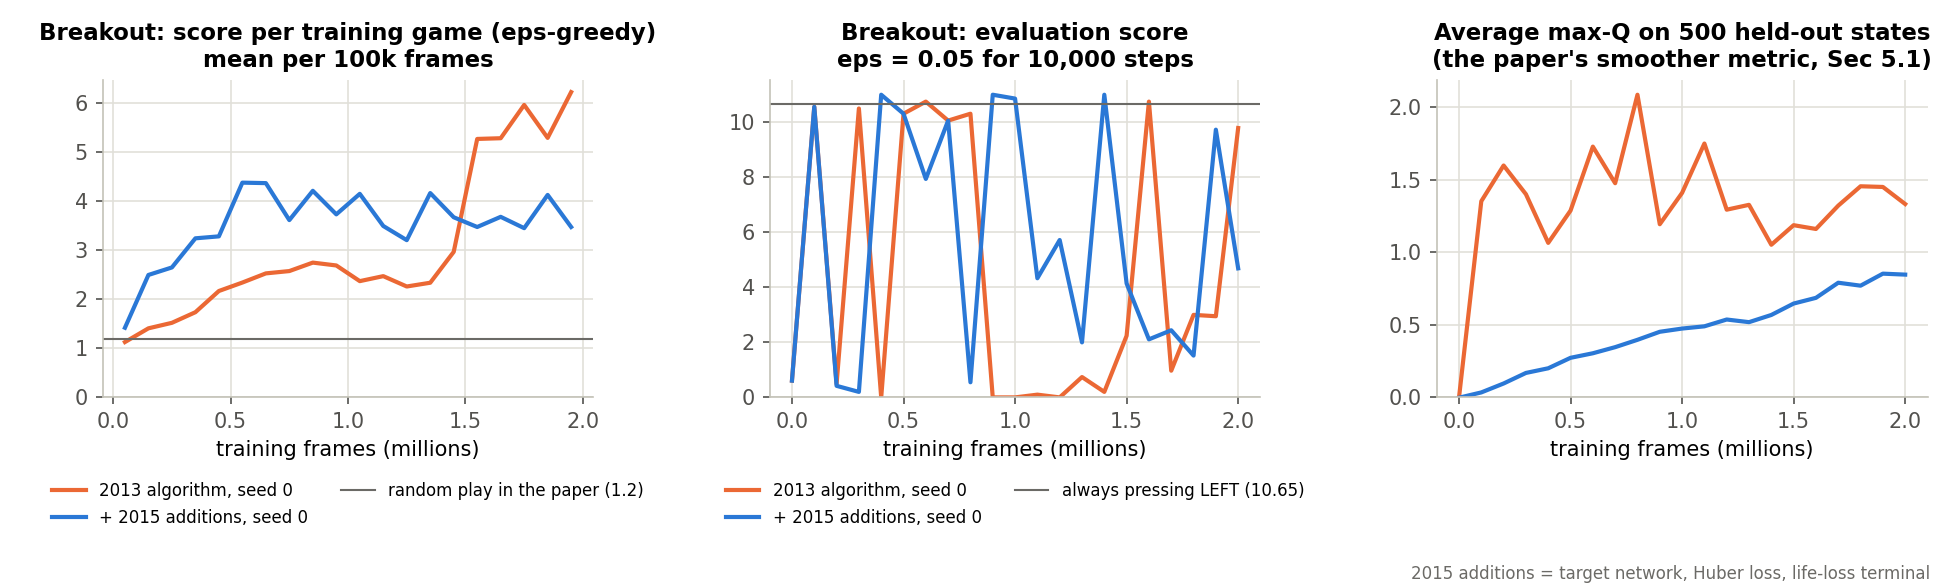

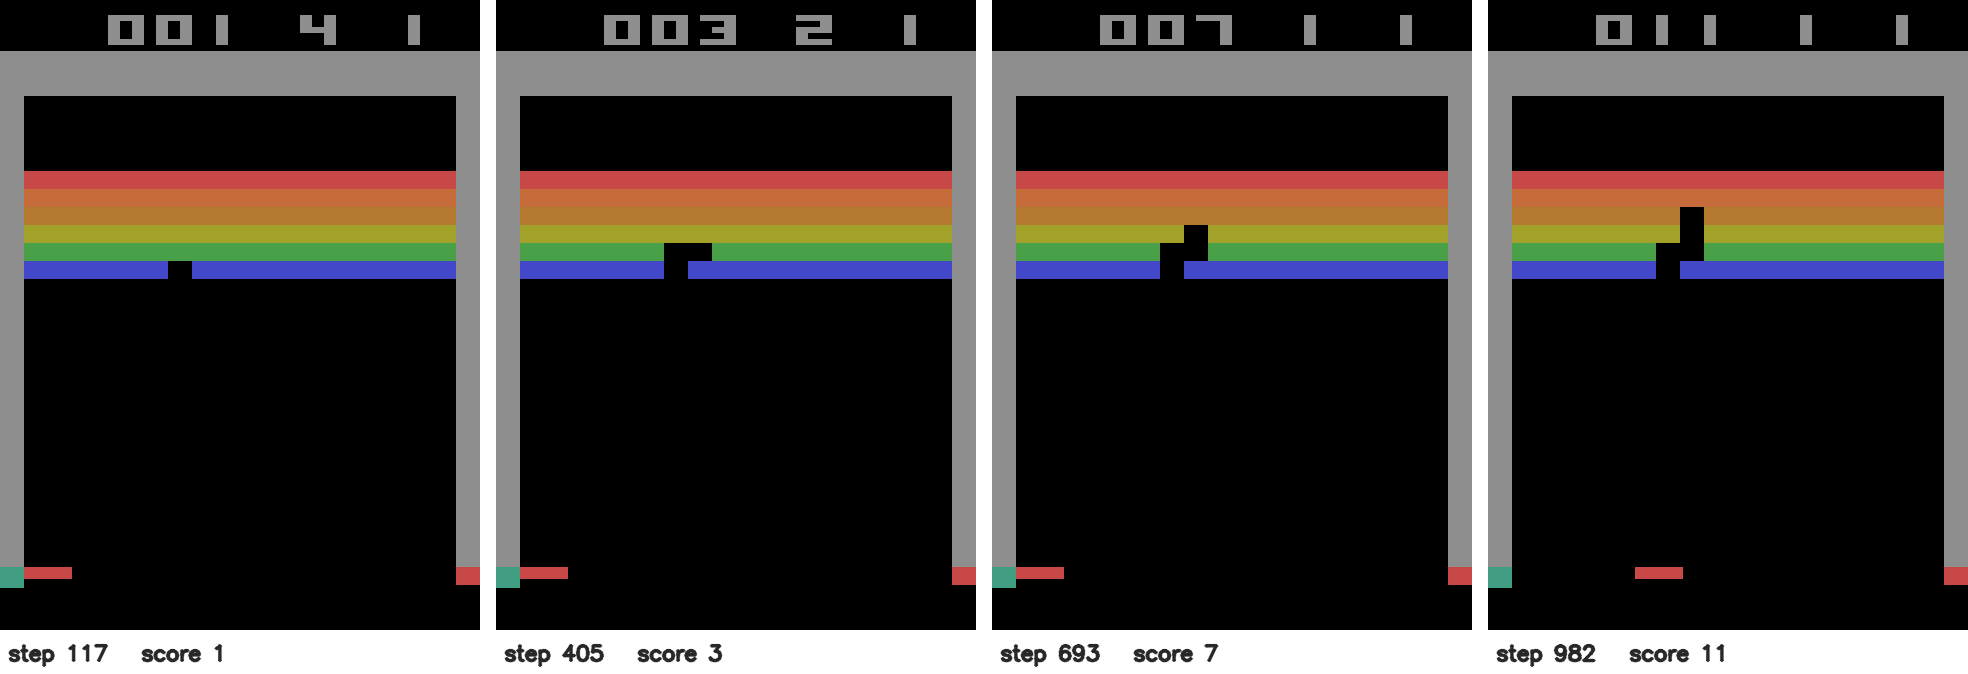

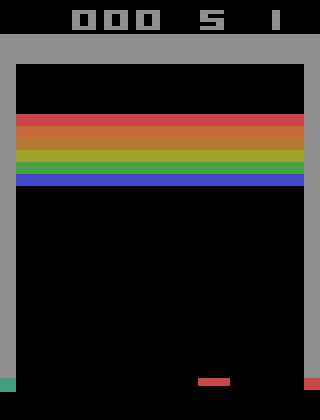

In [14]:
from IPython.display import Image, display
display(Image('figures/atari_training.png'))
display(Image('runs/breakout_cpu/watch/game_strip.png'))
display(Image('runs/breakout_cpu/watch/game.gif'))

## 5. Replay ablation (CartPole)

In [15]:
!python replay_ablation.py --out runs/ablation
!python plot_results.py --runs runs/breakout_cpu runs/breakout_cpu_2015fixes --ablation runs/ablation --out figures

arm=online    lr=0.0001 seed=0 mean return over last 10 evals=  17.5 [0.8 min]
arm=online    lr=0.0001 seed=1 mean return over last 10 evals=  16.4 [1.6 min]
arm=online    lr=0.0001 seed=2 mean return over last 10 evals=  17.0 [2.3 min]
arm=online    lr=0.0001 seed=3 mean return over last 10 evals=  16.9 [3.0 min]
arm=online    lr=0.0001 seed=4 mean return over last 10 evals=  25.1 [3.8 min]
arm=recent32  lr=0.0001 seed=0 mean return over last 10 evals=  75.4 [4.6 min]
arm=recent32  lr=0.0001 seed=1 mean return over last 10 evals= 138.0 [5.4 min]
arm=recent32  lr=0.0001 seed=2 mean return over last 10 evals=  91.6 [6.1 min]
arm=recent32  lr=0.0001 seed=3 mean return over last 10 evals= 176.4 [6.9 min]
arm=recent32  lr=0.0001 seed=4 mean return over last 10 evals=  61.6 [7.7 min]
arm=replay    lr=0.0001 seed=0 mean return over last 10 evals= 285.2 [8.6 min]
arm=replay    lr=0.0001 seed=1 mean return over last 10 evals= 264.5 [9.4 min]
arm=replay    lr=0.0001 seed=2 mean return over last

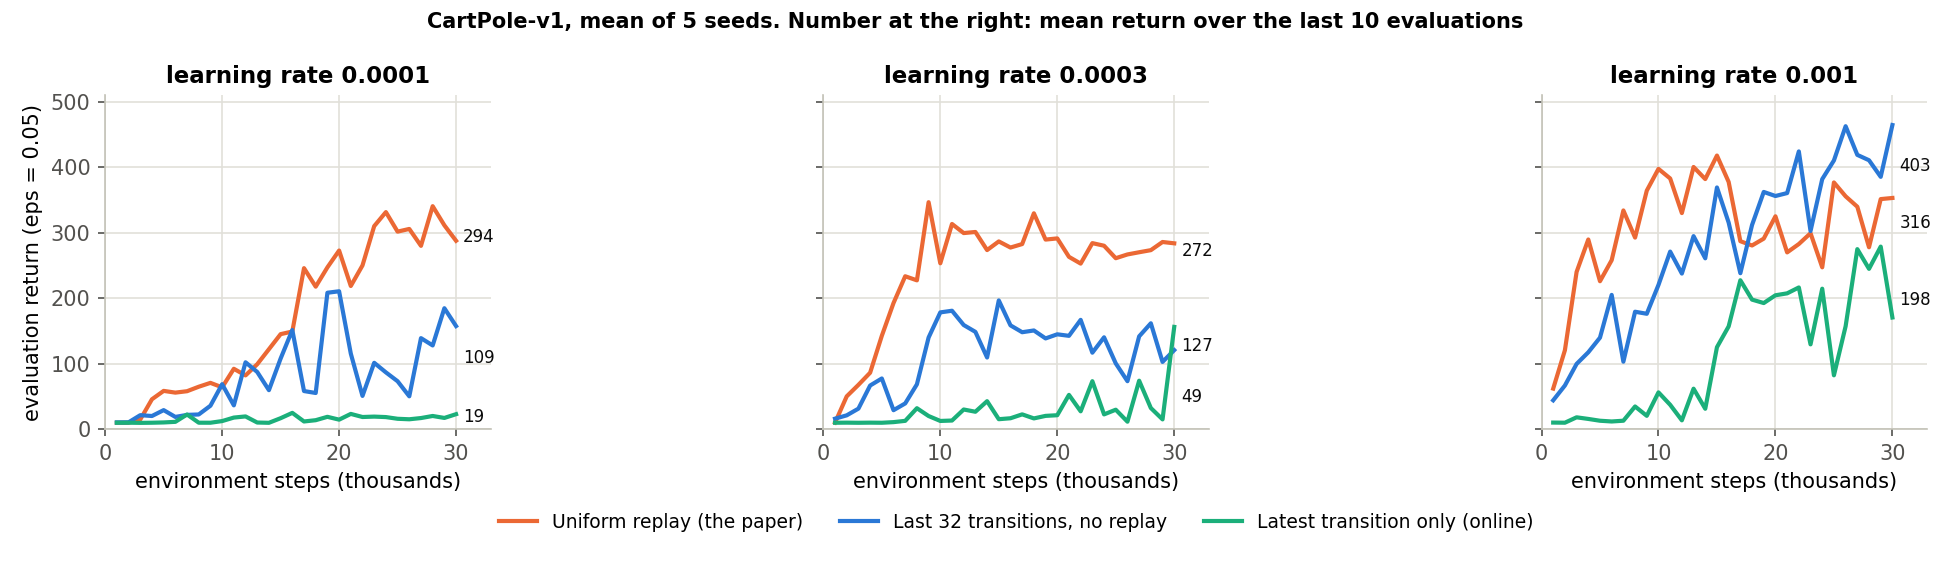

{
 "online|0.0001": {
  "arm": "online",
  "lr": 0.0001,
  "mean": 18.6,
  "std": 3.3,
  "per_seed": [
   17.5,
   16.4,
   17.0,
   16.9,
   25.1
  ]
 },
 "online|0.0003": {
  "arm": "online",
  "lr": 0.0003,
  "mean": 49.3,
  "std": 33.1,
  "per_seed": [
   90.8,
   18.2,
   15.0,
   35.3,
   87.1
  ]
 },
 "online|0.001": {
  "arm": "online",
  "lr": 0.001,
  "mean": 197.7,
  "std": 77.0,
  "per_seed": [
   67.2,
   256.1,
   151.3,
   253.5,
   260.2
  ]
 },
 "recent32|0.0001": {
  "arm": "recent32",
  "lr": 0.0001,
  "mean": 108.6,
  "std": 42.6,
  "per_seed": [
   75.4,
   138.0,
   91.6,
   176.4,
   61.6
  ]
 },
 "recent32|0.0003": {
  "arm": "recent32",
  "lr": 0.0003,
  "mean": 126.7,
  "std": 37.5,
  "per_seed": [
   95.1,
   91.7,
   101.7,
   171.4,
   173.4
  ]
 },
 "recent32|0.001": {
  "arm": "recent32",
  "lr": 0.001,
  "mean": 402.5,
  "std": 76.1,
  "per_seed": [
   469.9,
   449.4,
   392.6,
   441.5,
   258.9
  ]
 },
 "replay|0.0001": {
  "arm": "replay",
  "lr": 0.

In [16]:
display(Image('figures/replay_ablation.png'))
import json; print(json.dumps(json.load(open('runs/ablation/summary.json'))['summary'], indent=1))

## 6. For Results
Download `runs/` and `figures/` (logs, configs, checkpoints, plots) and commit them to the group repository.

In [17]:
!zip -qr results.zip runs figures && ls -la results.zip

-rw-r--r-- 1 root root 10460169 Oct 11 15:38 results.zip
